# 2. ASTF retrieval and the duration table

The rupture of an earthquake lasts a fraction of a second for a magnitude 3 event, and it looks shorter at
stations the rupture moves toward. These **apparent source time functions (ASTFs)** are recovered by removing the
path and site effects from the target record with an **empirical Green's function (EGF)**: the record of a smaller,
nearby earthquake at the same station, whose own rupture is short enough to treat as a spike. The removal is a
deconvolution; `bayes2mt` uses the **projected Landweber deconvolution (PLD)**, which keeps the ASTF positive and
non-zero only inside a chosen time window (the *support*).

This notebook goes from the waveforms and the deconvolution settings of every station (`picks.csv`, chosen with the
picker of notebook 1) to the table that the inversion (notebook 3) uses:

1. one station, direct S and the Moho-reflected S (SmS): windows, ASTFs, and the trade-off curve used to choose
   the support duration;
2. the retrieval figure of that station;
3. all stations and phases: ASTFs, quality control (variance reduction, VR ≥ 70 %), durations τc, take-off
   angles, onsets → `tauc_table.csv`;
4. the location of the target relative to its EGF from the ASTF onsets, and all ASTFs sorted by azimuth.

**Demo data:** the Mw 3.4 earthquake of 2020-05-03 in Haenam, South Korea, and its EGF (event 16 of Seo et al.,
2026). `data/event016/picks.csv` holds the deconvolution settings of every station: the ones used in the paper,
chosen station by station as in notebook 1.

In [1]:
import json
import time

import numpy as np
import pandas as pd
from obspy import read
from obspy.geodetics.base import gps2dist_azimuth

from bayes2mt import config, io, pld, relloc
from bayes2mt.plotting import plot_astf_retrieval, plot_astfs_by_azimuth, retrieval_waveforms, use_style

DATA = "data/event016"
event = json.load(open(f"{DATA}/event.json"))
picks = pld.read_picks(f"{DATA}/picks.csv")
print("font:", use_style())
print(f"{event['description']}")
print(f"{len(picks)} picks:", pd.Series([p.phase for p in picks]).value_counts().to_dict())

font: helvetica
2020-05-03 Mw 3.4 earthquake, Haenam, South Korea, and its empirical Green's function event
101 picks: {'S': 41, 'P': 41, 'SmS': 19}


## Step 1. One station: direct S and SmS at GOCB

For each phase the target and EGF records are cut around the target's pick (0.5 s before to 1.0 s after; the EGF
window starts at the same time relative to its origin time, so the ASTF keeps the travel-time difference between
the two events). The **trade-off curve** shows the misfit, 1 − VR/100, against the support duration: the misfit
drops while the support is shorter than the rupture and levels off once it contains it. The chosen duration sits at
the start of the plateau.

In [2]:
STATION = "GOCB"
sel = {p.phase: p for p in picks if p.station == STATION and p.phase in ("S", "SmS")}
astf, curve, windows = {}, {}, {}
for phase, p in sel.items():
    main, egf = io.sac_pair_paths(DATA, p.station, p.channel, pld.PHASE_SETUP[phase][0], network=p.network)
    windows[phase] = pld.prepare_windows(main, egf, p)
    astf[phase] = pld.retrieve_astf(windows[phase], p)
    curve[phase] = pld.tradeoff_curve(windows[phase].y, windows[phase].x, windows[phase].dt, p.start,
                                      pld.default_durations(p.start, windows[phase].dt))
    a = astf[phase]
    print(f"{phase:4s} support {p.start:+.2f} to {p.start + p.duration:+.2f} s: VR {a.vr:.1f} %, "
          f"tau_c {pld.characteristic_duration(a.t, a.f):.4f} s")

S    support -0.02 to +0.13 s: VR 97.1 %, tau_c 0.0807 s
SmS  support -0.01 to +0.08 s: VR 91.8 %, tau_c 0.0505 s


## Step 2. The retrieval figure

(a) Target and EGF records with the direct-S (blue) and SmS (purple) windows; (b, c) each target window and its
reconstruction, the EGF convolved with the ASTF; (d) the two ASTFs with their characteristic durations τc (bar)
centred on the centroid time (dot); (e) the trade-off curves with the chosen durations (dashed).

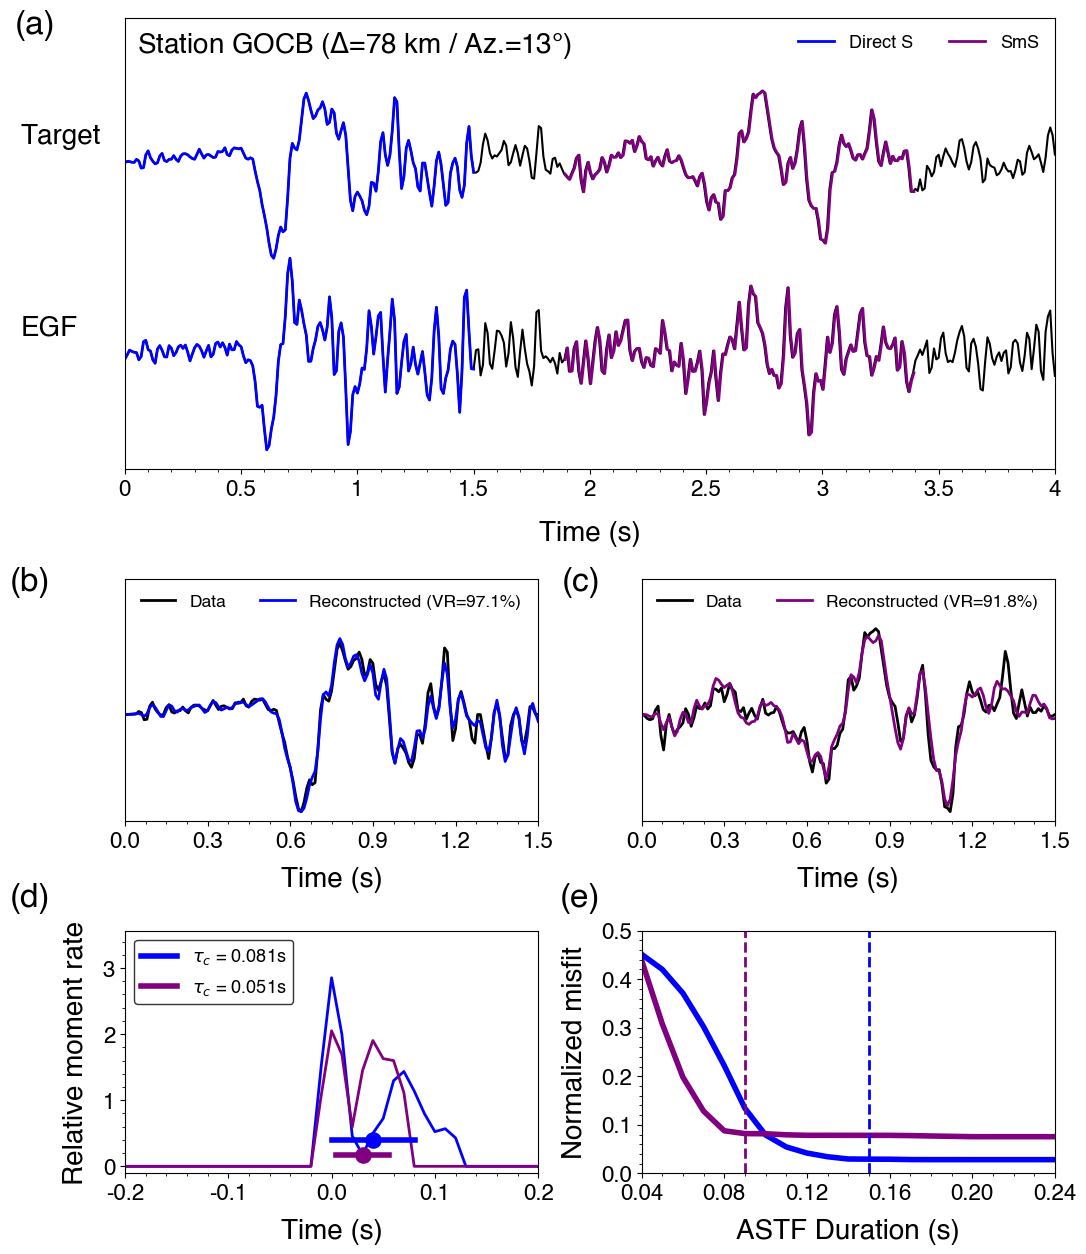

In [3]:
p = sel["S"]
main, egf = io.sac_pair_paths(DATA, p.station, p.channel, "T", network=p.network)
tr_main, tr_egf = read(main)[0], read(egf)[0]
dist_m, az, _ = gps2dist_azimuth(event["latitude"], event["longitude"], tr_main.stats.sac.stla, tr_main.stats.sac.stlo)
wf = retrieval_waveforms(tr_main, tr_egf, astf["S"], astf["SmS"])
fig, axes = plot_astf_retrieval(wf, astf["S"], astf["SmS"], curve["S"], curve["SmS"],
                                sel["S"].duration, sel["SmS"].duration, STATION, dist_m / 1000, az)

## Step 3. All stations and phases → the duration table

`pld.retrieve_from_picks` repeats Step 1 for every pick (P on the vertical component, S and SmS on the transverse).
`pld.duration_table` keeps the ASTFs with VR ≥ 70 % and adds, per station, the azimuth, the take-off angle (TauP,
1-D gradient model), the characteristic duration τc and the onset t1.

In [4]:
t0 = time.perf_counter()
astfs = pld.retrieve_from_picks(picks, DATA)
table = pld.duration_table(astfs, picks, DATA, event["latitude"], event["longitude"], event["depth_km"])
runtime = time.perf_counter() - t0
table.to_csv("tauc_table.csv", index=False)
n_all = pd.Series([a.phase for a in astfs]).value_counts().reindex(["P", "S", "SmS"])
n_kept = table.groupby("phase").size().reindex(["P", "S", "SmS"])
print(f"{len(astfs)} ASTFs in {runtime:.1f} s; kept after VR >= {config.VR_THRESHOLD:.0f} %:",
      dict(zip(n_kept.index, n_kept.values)), "of", dict(zip(n_all.index, n_all.values)))
table.groupby("phase")[["vr", "tauc"]].describe().round(3)

101 ASTFs in 21.3 s; kept after VR >= 70 %: {'P': np.int64(34), 'S': np.int64(39), 'SmS': np.int64(15)} of {'P': np.int64(41), 'S': np.int64(41), 'SmS': np.int64(19)}


vr                                                         tauc  \
      count    mean    std     min     25%     50%     75%     max count   
phase                                                                      
P      34.0  87.589  6.771  72.134  83.410  87.957  92.673  97.296  34.0   
S      39.0  89.253  6.541  73.377  84.491  90.118  94.393  97.768  39.0   
SmS    15.0  84.166  6.769  74.576  79.848  82.721  89.728  98.325  15.0   

                                                        
        mean    std    min    25%    50%    75%    max  
phase                                                   
P      0.055  0.009  0.036  0.050  0.056  0.060  0.074  
S      0.068  0.017  0.035  0.053  0.073  0.080  0.096  
SmS    0.047  0.007  0.029  0.044  0.048  0.052  0.054

## Step 4. Relative location and the ASTFs by azimuth

With origin-time alignment, the onset of an ASTF is the travel-time difference between target and EGF, which
varies with azimuth and take-off angle. `relloc.locate` grid-searches the offset of the target from the EGF that
predicts the onsets best; the predicted onsets are the black bars below. The ASTFs are drawn with unit area, so a
shorter ASTF is taller.

target relative to EGF: azimuth 102.0 deg, 104.9 deg from vertical down, 67 m (RMS onset misfit 5.0 ms)


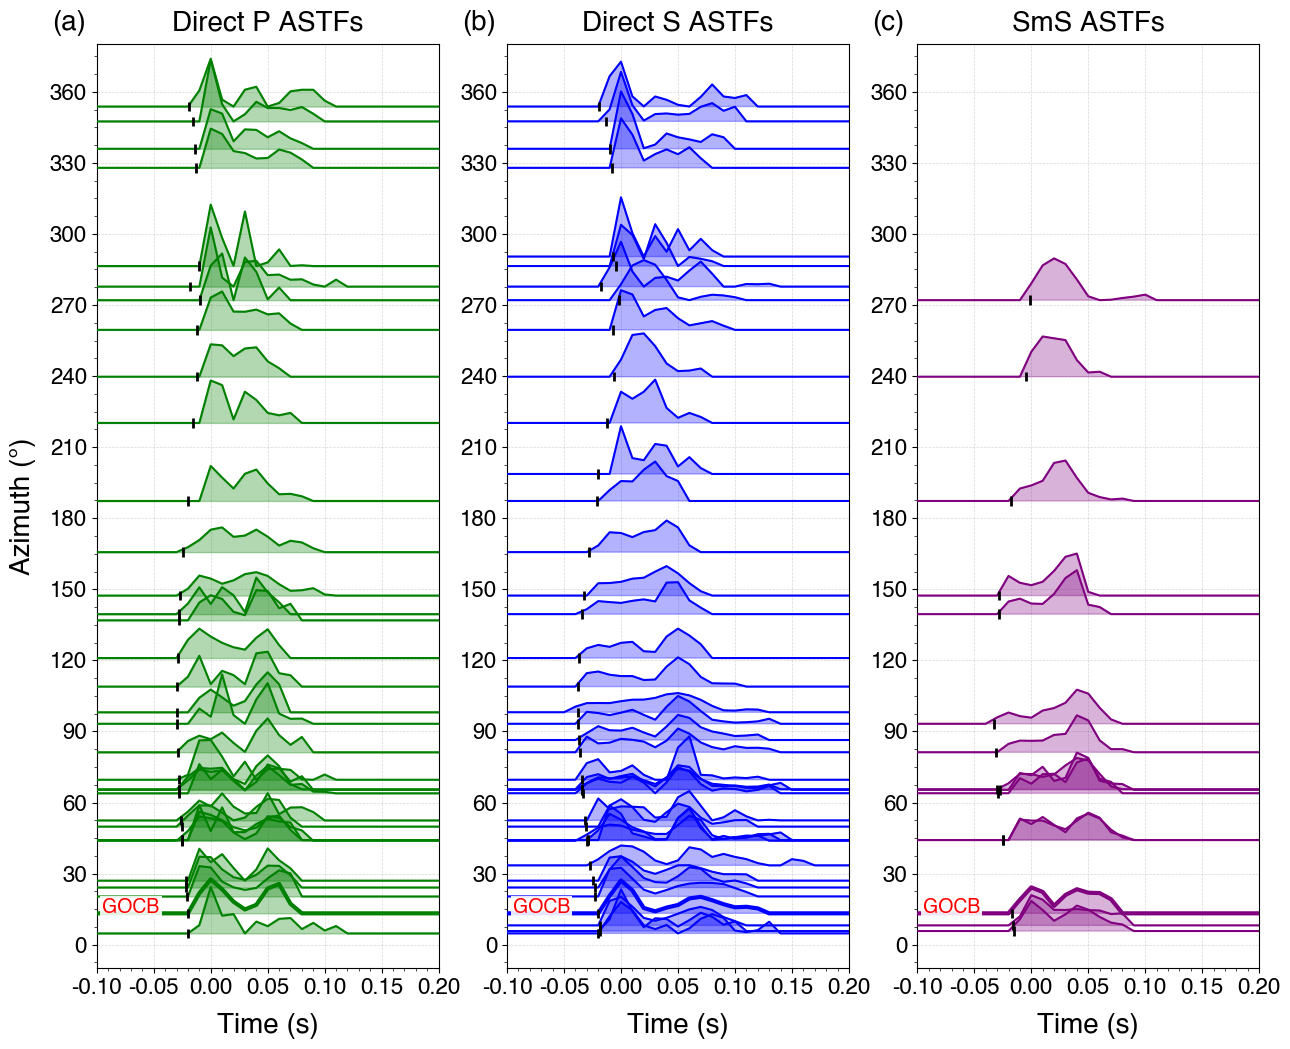

In [5]:
loc = relloc.locate(table, vp=event["vp_km_s"] * 1000, vs=event["vs_km_s"] * 1000)
print(f"target relative to EGF: azimuth {loc.azimuth:.1f} deg, {loc.dip:.1f} deg from vertical down, "
      f"{loc.L:.0f} m (RMS onset misfit {1000 * loc.misfit:.1f} ms)")
by_key = {(a.code, a.phase): a for a in astfs}
panels = []
for phase in ["P", "S", "SmS"]:
    rows = table[table.phase == phase]
    v = (event["vp_km_s"] if phase == "P" else event["vs_km_s"]) * 1000
    onsets = relloc.predict_onsets(loc.azimuth, loc.dip, loc.t0, loc.L, rows.azimuth, rows.toa, v)
    panels.append(([by_key[(c, phase)] for c in rows.code], rows.azimuth.to_numpy(), np.asarray(onsets)))
fig, axes = plot_astfs_by_azimuth(panels, highlight=STATION)

## Summary

In [6]:
print(f'''ASTF retrieval of the demo event
================================
{len(astfs)} ASTFs from {len(picks)} picks in {runtime:.1f} s; {len(table)} pass VR >= {config.VR_THRESHOLD:.0f} %:
  {dict(zip(n_kept.index, n_kept.values))}
tau_c: P median {table[table.phase=="P"].tauc.median():.4f} s, S {table[table.phase=="S"].tauc.median():.4f} s, SmS {table[table.phase=="SmS"].tauc.median():.4f} s
station {STATION}: direct S VR {astf["S"].vr:.1f} %, SmS VR {astf["SmS"].vr:.1f} %
relative location: {loc.L:.0f} m toward azimuth {loc.azimuth:.0f} deg, {loc.dip:.0f} deg from vertical down
file: tauc_table.csv (input of notebook 3)''')

ASTF retrieval of the demo event
101 ASTFs from 101 picks in 21.3 s; 88 pass VR >= 70 %:
  {'P': np.int64(34), 'S': np.int64(39), 'SmS': np.int64(15)}
tau_c: P median 0.0558 s, S 0.0728 s, SmS 0.0482 s
station GOCB: direct S VR 97.1 %, SmS VR 91.8 %
relative location: 67 m toward azimuth 102 deg, 105 deg from vertical down
file: tauc_table.csv (input of notebook 3)


## Take-home points

- One pick per station and phase (window start, support duration, EGF shift) fully defines the deconvolution; the
  same picks always give the same ASTFs.
- The trade-off curve guides the support duration: choose the start of the plateau, not a longer support.
- The apparent durations vary with azimuth (shorter where the rupture approaches); notebook 3 inverts this pattern
  for the rupture's size, duration and direction.
- SmS ASTFs leave the source downward; they constrain the rupture along dip, which direct waves at the surface
  sample poorly.